# Quantitative validation experiments

These are actual recorded runs, not newly invented notebook metrics. Historical
Dorian/Journey/Cask results have different splits from the new source-family
cohort and must not be pooled. No test is rerun here. The new full training run
is pending; its learning curve is loaded only when real saved results exist.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from types import SimpleNamespace
from collections import Counter
from dataclasses import dataclass, asdict
from functools import lru_cache
import collections, csv, hashlib, html, io, json, math, random, re, statistics, string, subprocess, sys, time, zipfile
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, HTML, SVG
ROOT=Path.cwd().resolve()
if not (ROOT/"src").is_dir(): ROOT=ROOT.parent
assert (ROOT/"src").is_dir(), "Run in this repository"
FIGURES=ROOT/"assets/plots"
FIGURES.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({"svg.fonttype":"none", "font.size":10, "axes.spines.top":False, "axes.spines.right":False})
def sha(raw):
    return hashlib.sha256(raw).hexdigest()
def read_json(relative):
    return json.loads((ROOT/relative).read_text(encoding="utf-8"))
def table(rows,columns,caption):
    header="".join("<th>"+html.escape(str(c))+"</th>" for c in columns)
    body="".join("<tr>"+"".join("<td>"+html.escape(str(r.get(c,"")))+"</td>" for c in columns)+"</tr>" for r in rows)
    display(HTML("<table><caption>"+html.escape(caption)+"</caption><thead><tr>"+header+"</tr></thead><tbody>"+body+"</tbody></table>"))
def show_figure(fig,name):
    fig.tight_layout()
    fig.savefig(FIGURES/(name+".png"),dpi=160)
    fig.savefig(FIGURES/(name+".svg"))
    display(SVG((FIGURES/(name+".svg")).read_text(encoding="utf-8")))
    plt.close(fig)
print("Analysis kernel ready. No model weights loaded.")


Analysis kernel ready. No model weights loaded.


In [2]:
history=read_json("docs/v4-cached-validation-results.json")
rows=[]
for i,r in enumerate(history["results"]):
    rows.append({"index":i,"policy":r["policy"]["method"]+" "+str(r["policy"]["magnitude"]),
                 "answer F1 %":round(100*r["token_f1"],3),"EM %":round(100*r["exact_match"],3),
                 "coverage %":round(100*r["answer_coverage"],2),"accepted EM mismatches":r["accepted_gold_em_mismatches"],
                 "control false":r["control_false_answers"],"promoted":r["meets_prespecified_promotion"]})
table(rows,list(rows[0]),"Historical cached Dorian validation: 29 QA and 4 authored controls")
print("Qualified winner:",history["qualified_winner"])


index,policy,answer F1 %,EM %,coverage %,accepted EM mismatches,control false,promoted
0,baseline 0,8.775,6.897,93.1,25,0,False
1,source_consensus 0.5,8.775,6.897,93.1,25,0,False
2,source_consensus 1,8.775,6.897,93.1,25,0,False
3,source_consensus 2,8.775,6.897,93.1,25,0,False
4,ambiguity_gap 1,5.327,3.448,68.97,19,0,False
5,ambiguity_gap 2,4.516,3.448,58.62,16,0,False
6,ambiguity_gap 4,1.067,0.0,37.93,11,0,False
7,cross_reader_agreement -2,9.113,6.897,37.93,9,0,False
8,cross_reader_agreement 0,3.941,3.448,17.24,4,0,False
9,cross_reader_agreement 2,3.941,3.448,10.34,2,0,False


Qualified winner: None


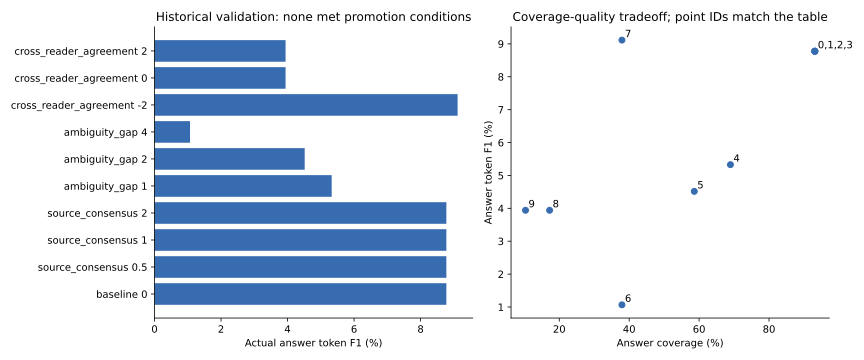

In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,5))
labels=[r["policy"]["method"]+" "+str(r["policy"]["magnitude"]) for r in history["results"]]
axes[0].barh(labels,[100*r["token_f1"] for r in history["results"]],color="#386cb0")
axes[0].set(xlabel="Actual answer token F1 (%)",title="Historical validation: none met promotion conditions")
axes[1].scatter([100*r["answer_coverage"] for r in history["results"]],[100*r["token_f1"] for r in history["results"]],color="#386cb0")
point_ids={}
for i,r in enumerate(history["results"]):
    point=(100*r["answer_coverage"],100*r["token_f1"])
    point_ids.setdefault(point,[]).append(str(i))
for point,ids in point_ids.items():
    axes[1].annotate(",".join(ids),point,xytext=(3,3),textcoords="offset points")
axes[1].set(xlabel="Answer coverage (%)",ylabel="Answer token F1 (%)",title="Coverage-quality tradeoff; point IDs match the table")
show_figure(fig,"historical-validation-tradeoff")


## Historical held-out results

These books were fresh at their original evaluation and have since been observed.
Their scores are context, not policy-selection input for this round and not fresh
repeat claims. Only aggregate fields are displayed, never private QA cases.


In [4]:
journey=read_json("docs/v2-reader-locked-test.json")
cask=read_json("docs/v3-reader-locked-test.json")
table([{"source":"Journey (observed)","recorded aggregate":json.dumps(journey["fresh_test"],sort_keys=True)},
       {"source":"Cask (observed)","recorded aggregate":json.dumps(cask["fresh_test"],sort_keys=True)}],
      ["source","recorded aggregate"],"Historical original test results; no rescore")


source,recorded aggregate
Journey (observed),"{""abstention_rate"": 0.18518518518518517, ""control_false_answer_rate"": null, ""exact_match"": 0.037037037037037035, ""queries"": 27, ""token_f1"": 0.0832637148426622}"
Cask (observed),"{""abstention_rate"": 0.17857142857142858, ""accepted_answers"": 23, ""accepted_exact_source_checks"": 23, ""exact_match"": 0.14285714285714285, ""no_answer_controls"": 0, ""queries"": 28, ""semantic_entailment_proven"": false, ""token_f1"": 0.1984126984126984}"


## New source-family validation evidence

This score compares returned sections with human evidence annotations before
context truncation. It is not answer EM/F1. Story routing is supplied.


origin,questions,evidence recall@4
andersen-fairybook,100,0.9117
blue-fairybook,100,0.745
green-fairybook,100,0.91
lilac-fairybook,100,0.7917


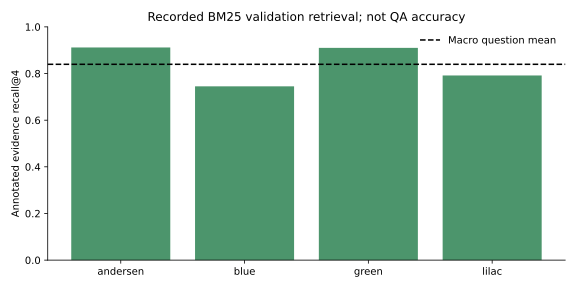

In [5]:
retrieval=read_json("docs/v5-validation-retrieval-baseline.json")
table([{"origin":o,"questions":r["n"],"evidence recall@4":round(r["recall_at_4"],4)} for o,r in retrieval["per_origin"].items()],
      ["origin","questions","evidence recall@4"],"Actual fixed 400-question validation cohort")
fig,ax=plt.subplots(figsize=(8,4))
ax.bar([o.replace("-fairybook","") for o in retrieval["per_origin"]],[r["recall_at_4"] for r in retrieval["per_origin"].values()],color="#4c956c")
ax.axhline(retrieval["recall_at_4"],color="black",linestyle="--",label="Macro question mean")
ax.set(ylim=(0,1),ylabel="Annotated evidence recall@4",title="Recorded BM25 validation retrieval; not QA accuracy")
ax.legend(frameon=False)
show_figure(fig,"validation-evidence-by-origin")


## Actual CPU optimization and persistence smoke

Four training examples and two validation examples test mechanics, not general
QA quality. The model had no missing or newly initialized parameters and the
saved checkpoint reproduced both answers. This is a recorded cloud run, not a
claim that the notebook just trained a full model.


In [6]:
smoke=read_json("docs/v5-cpu-smoke.json")
table([{"model":smoke["model"]["name"],"CPU seconds":round(smoke["runtime"]["wall_seconds"],2),"train QA":smoke["train_examples"],
        "validation QA":smoke["validation_examples"],"mean train loss":round(smoke["train_loss"],4),"replay identical":smoke["checkpoint_reload"]["answers_identical"]}],
      ["model","CPU seconds","train QA","validation QA","mean train loss","replay identical"],"Actual CPU mechanics receipt")
print("Loading diagnostics:",smoke["loading_info"])
print("Initial weights SHA256:",smoke["pretrained_weights_sha256"])
if "validation_history" in smoke:
    table(smoke["validation_history"],list(smoke["validation_history"][0]),"Actual two-example smoke history; not full-data performance")


model,CPU seconds,train QA,validation QA,mean train loss,replay identical
google-t5/t5-small,79.77,4,2,0.4628,True


Loading diagnostics: {'missing_keys': [], 'unexpected_keys': [], 'mismatched_keys': [], 'error_msgs': []}
Initial weights SHA256: bd944e5f1b3ad9b70dd9d00010a517059e19265671076b8b0a4a58d9491842bc


epoch,validation_examples,answer_token_f1,exact_match,source_citation_validity
0,2,0.42857142857142855,0.0,1.0
1,2,0.42857142857142855,0.0,1.0


## Full-data learning curves when the job completes

This reads saved aggregate metrics only: no training, test scoring or fabricated
placeholder points. Set the ignored downloaded run folder after completion.


In [7]:
FULL_RUN=ROOT/"data/interim/v5-cpu-full-results/experiment/run"
curve_path=FULL_RUN/"validation-results.json"
if curve_path.exists():
    curve=json.loads(curve_path.read_text(encoding="utf-8"))
    table([{"epoch":r["epoch"],"answer F1":round(r["validation"]["f1"],4),"EM":round(r["validation"]["em"],4),"n":r["validation"]["n"]} for r in curve],
          ["epoch","answer F1","EM","n"],"Actual saved full-data validation metrics")
    fig,axes=plt.subplots(1,2,figsize=(10,4))
    axes[0].plot([r["epoch"] for r in curve],[r["validation"]["f1"] for r in curve],marker="o")
    axes[0].set(xlabel="Epoch (0 = untuned)",ylabel="Actual validation answer token F1")
    learned=[r for r in curve if "loss" in r]
    axes[1].plot([r["epoch"] for r in learned],[r["loss"] for r in learned],marker="o")
    axes[1].set(xlabel="Epoch",ylabel="Actual mean training loss")
    show_figure(fig,"full-training-learning-curve")
else:
    print("Full training still running: no full-data curve or answer score is available yet.")


Full training still running: no full-data curve or answer score is available yet.
